In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as mp
import seaborn as sb

In [2]:
df=pd.read_csv(r"E:\Power BI project for ANUDIP\food_delivery_master.csv")



In [3]:
df.columns


Index(['order_id', 'order_timestamp', 'order_date', 'order_hour',
       'day_of_week', 'is_weekend', 'day_type', 'peak_hour', 'customer_id',
       'customer_age', 'customer_type', 'customer_rating', 'restaurant_id',
       'restaurant_type', 'restaurant_category', 'restaurant_rating',
       'restaurant_preparation_time_min', 'items_count', 'driver_id',
       'driver_experience_months', 'driver_rating', 'city', 'delivery_area',
       'distance_km', 'weather', 'traffic_level',
       'estimated_delivery_time_min', 'actual_delivery_time_min',
       'delivery_delay_min', 'late_delivery', 'delay_category', 'order_status',
       'is_cancelled', 'cancellation_reason', 'subtotal', 'discount_percent',
       'tax_amount', 'service_fee', 'delivery_fee', 'order_total',
       'tip_amount', 'payment_method'],
      dtype='object')

In [4]:
df['order_status'].value_counts()

order_status
Completed    49132
Cancelled      868
Name: count, dtype: int64

In [5]:
total_orders = df['order_id'].nunique()

print("Total Orders:", total_orders)

Total Orders: 50000


In [6]:
completed_orders = (
    df['order_status'] == 'Completed'
).sum()

print("Completed Orders:", completed_orders)


Completed Orders: 49132


In [7]:
cancelled_orders = (
    df['order_status'] == 'Cancelled'
).sum()

print("Cancelled Orders:", cancelled_orders)

Cancelled Orders: 868


In [8]:
on_time_deliveries = (
    (df['order_status'] == 'Completed') &
    (df['late_delivery'] == 0)
).sum()

print("On-Time Deliveries:", on_time_deliveries)

On-Time Deliveries: 31164


In [9]:
late_deliveries = (
    (df['order_status'] == 'Completed') &
    (df['late_delivery'] == 1)
).sum()

print("Late Deliveries:", late_deliveries)

Late Deliveries: 17968


In [10]:
late_delivery_pct = (
    late_deliveries / completed_orders
) * 100

print("Late Delivery %:", round(late_delivery_pct, 2), "%")

Late Delivery %: 36.57 %


In [11]:
average_delivery_time = df.loc[
    df['order_status'] == 'Completed',
    'actual_delivery_time_min'
].mean()

print(
    "Average Delivery Time:",
    round(average_delivery_time, 2),
    "minutes"
)

Average Delivery Time: 35.15 minutes


In [12]:
average_delay = df.loc[
    df['order_status'] == 'Completed',
    'delivery_delay_min'
].mean()

print(
    "Average Delay:",
    round(average_delay, 2),
    "minutes"
)

Average Delay: 4.23 minutes


In [13]:
average_late_delay = df.loc[
    (df['order_status'] == 'Completed') &
    (df['late_delivery'] == 1),
    'delivery_delay_min'
].mean()

print(
    "Average Delay Among Late Deliveries:",
    round(average_late_delay, 2),
    "minutes"
)

Average Delay Among Late Deliveries: 9.7 minutes


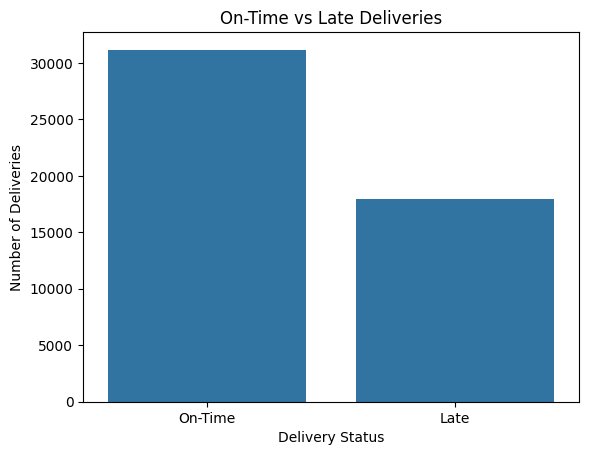

In [14]:
delivery = pd.Series({
    'On-Time': on_time_deliveries,
    'Late': late_deliveries
})

sb.barplot(x=delivery.index, y=delivery.values)

mp.title("On-Time vs Late Deliveries")
mp.xlabel("Delivery Status")
mp.ylabel("Number of Deliveries")

mp.show()

In [15]:
traffic_analysis = df.groupby('traffic_level').agg(
    orders=('order_id', 'nunique'),
    average_delivery_time=('actual_delivery_time_min', 'mean'),
    average_delay=('delivery_delay_min', 'mean'),
    late_delivery_percentage=('late_delivery', 'mean')
).reset_index()

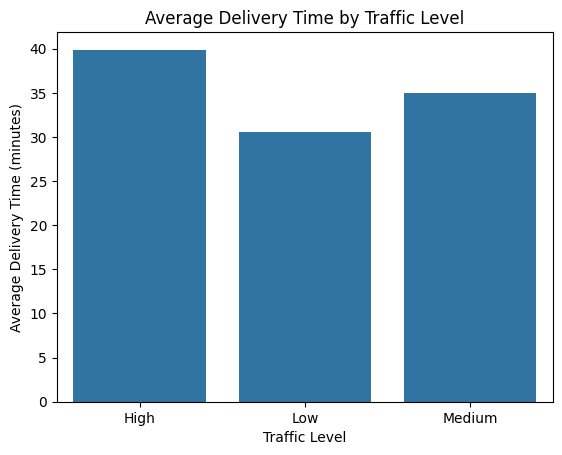

In [16]:
sb.barplot(
    data=traffic_analysis,
    x='traffic_level',
    y='average_delivery_time'
)

mp.title('Average Delivery Time by Traffic Level')
mp.xlabel('Traffic Level')
mp.ylabel('Average Delivery Time (minutes)')
mp.show()

In [17]:
df['distance_group'] = pd.cut(
    df['distance_km'],
    bins=[0, 3, 6, 10, float('inf')],
    labels=['0–3 km', '3–6 km', '6–10 km', '10+ km'],
    include_lowest=True
)

distance_analysis = df.groupby('distance_group', observed=False).agg(
    orders=('order_id', 'nunique'),
    average_delivery_time=('actual_delivery_time_min', 'mean'),
    average_delay=('delivery_delay_min', 'mean'),
    late_delivery_percentage=('late_delivery', 'mean')
).reset_index()

distance_analysis['late_delivery_percentage'] *= 100

print(distance_analysis)

  distance_group  orders  average_delivery_time  average_delay  \
0         0–3 km   15093              25.041905       3.368254   
1         3–6 km   23154              33.600088       4.091672   
2        6–10 km    9192              46.507481       5.237504   
3         10+ km    2561              68.180804       7.012346   

   late_delivery_percentage  
0                 31.112309  
1                 36.585366  
2                 42.679818  
3                 46.754281  


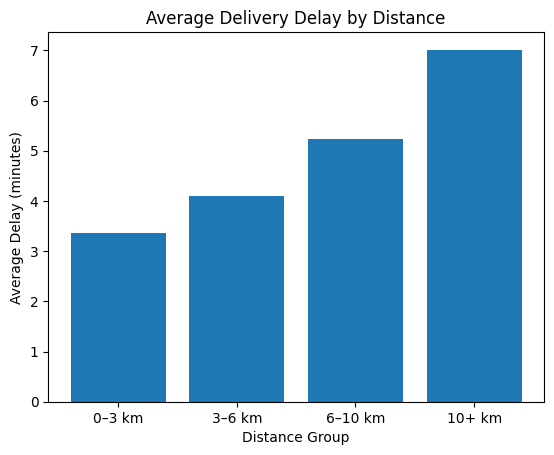

In [18]:
mp.bar(
    distance_analysis['distance_group'].astype(str),
    distance_analysis['average_delay']
)

mp.xlabel('Distance Group')
mp.ylabel('Average Delay (minutes)')
mp.title('Average Delivery Delay by Distance')
mp.show()

In [19]:
df['preparation_group'] = pd.cut(
    df['restaurant_preparation_time_min'],
    bins=[0, 15, 30, 45, float('inf')],
    labels=['Fast', 'Medium', 'Slow', 'Very Slow'],
    include_lowest=True
)

preparation_analysis = df.groupby('preparation_group', observed=False).agg(
    orders=('order_id', 'nunique'),
    average_preparation_time=('restaurant_preparation_time_min', 'mean'),
    average_delivery_time=('actual_delivery_time_min', 'mean'),
    average_delay=('delivery_delay_min', 'mean'),
    late_delivery_percentage=('late_delivery', 'mean')
).reset_index()

preparation_analysis['late_delivery_percentage'] *= 100

print(preparation_analysis)

  preparation_group  orders  average_preparation_time  average_delivery_time  \
0              Fast   28948                 10.706474              30.320179   
1            Medium   18993                 20.639025              40.180641   
2              Slow    1878                 35.182641              55.245937   
3         Very Slow     181                 52.370166              73.210843   

   average_delay  late_delivery_percentage  
0       3.098238                 27.156977  
1       5.731125                 49.034191  
2       6.359697                 54.008667  
3       6.216867                 51.807229  


In [20]:
peak_analysis = df.groupby('peak_hour').agg(
    orders=('order_id', 'nunique'),
    average_delay=('delivery_delay_min', 'mean'),
    late_delivery_percentage=('late_delivery', 'mean'),
    cancellation_percentage=('is_cancelled', 'mean')
).reset_index()

peak_analysis['late_delivery_percentage'] *= 100
peak_analysis['cancellation_percentage'] *= 100

print(peak_analysis)

   peak_hour  orders  average_delay  late_delivery_percentage  \
0          0   19168       4.088940                 35.814175   
1          1   30832       4.322602                 37.043036   

   cancellation_percentage  
0                 1.512938  
1                 1.874676  


In [21]:
def get_time_period(hour):
    if 5 <= hour < 11:
        return 'Breakfast'
    elif 11 <= hour < 15:
        return 'Lunch'
    elif 15 <= hour < 18:
        return 'Evening'
    elif 18 <= hour < 23:
        return 'Dinner'
    else:
        return 'Late Night'

df['time_period'] = df['order_hour'].apply(get_time_period)

In [22]:
time_analysis = df.groupby('time_period').agg(
    orders=('order_id', 'nunique'),
    average_delay=('delivery_delay_min', 'mean'),
    late_delivery_percentage=('late_delivery', 'mean'),
    cancellation_percentage=('is_cancelled', 'mean')
).reset_index()

time_analysis['late_delivery_percentage'] *= 100

print(time_analysis)

  time_period  orders  average_delay  late_delivery_percentage  \
0   Breakfast    8972       4.090332                 35.804148   
1      Dinner   17983       4.281190                 36.668555   
2     Evening    5456       4.205477                 36.717586   
3  Late Night    3006       3.971746                 34.981500   
4       Lunch   14583       4.325464                 37.197933   

   cancellation_percentage  
0                 0.016607  
1                 0.018517  
2                 0.016129  
3                 0.010978  
4                 0.018172  


In [23]:
weather_analysis = df.groupby('weather').agg(
    orders=('order_id', 'nunique'),
    average_delay=('delivery_delay_min', 'mean'),
    late_delivery_percentage=('late_delivery', 'mean'),
    cancellation_percentage=('is_cancelled', 'mean'),
    average_delivery_time=('actual_delivery_time_min', 'mean')
).reset_index()

weather_analysis['late_delivery_percentage'] *= 100
weather_analysis['cancellation_percentage'] *= 100

print(weather_analysis)

  weather  orders  average_delay  late_delivery_percentage  \
0   Clear   28248       2.547367                 24.492946   
1  Cloudy   12810       4.294810                 38.764804   
2    Rain    7627       8.502087                 69.180019   
3   Storm    1315      15.648777                 89.187056   

   cancellation_percentage  average_delivery_time  
0                 1.384169              33.555803  
1                 1.787666              35.121532  
2                 2.622263              39.159418  
3                 3.650190              47.072612  


In [24]:
completed_df = df[df['order_status'] == 'Completed']

area_analysis = completed_df.groupby('delivery_area').agg(
    orders=('order_id', 'nunique'),
    average_delay=('delivery_delay_min', 'mean'),
    late_percentage=('late_delivery', 'mean')
).reset_index()

area_analysis['late_percentage'] *= 100

top_10_areas = area_analysis[
    area_analysis['orders'] >= 100
].sort_values(
    'late_percentage', ascending=False
).head(10)

print(top_10_areas)

     delivery_area  orders  average_delay  late_percentage
13   City_B_Area_3    1520       4.648026        40.921053
2    City_A_Area_2    1958       4.525026        39.172625
16   City_B_Area_6    1480       4.744595        39.054054
11  City_B_Area_10    1421       4.703026        38.986629
1   City_A_Area_10    1897       4.406958        38.692673
3    City_A_Area_3    1931       4.510616        38.529259
17   City_B_Area_7    1479       4.437458        38.471941
0    City_A_Area_1    2020       4.301485        38.217822
8    City_A_Area_8    1935       4.287339        38.139535
18   City_B_Area_8    1505       4.766113        38.073090


In [25]:
completed_df = df[df['order_status'] == 'Completed']
restaurant_analysis = completed_df.groupby('restaurant_id').agg(
    orders=('order_id', 'nunique'),
    rating=('restaurant_rating', 'mean'),
    preparation_time=('restaurant_preparation_time_min', 'mean'),
    late_percentage=('late_delivery', 'mean'),
    average_delay=('delivery_delay_min', 'mean')
).reset_index()
restaurant_analysis['late_percentage'] *= 100

top_10_restaurants = restaurant_analysis[
    restaurant_analysis['orders'] >= 100
].sort_values(
    'late_percentage', ascending=False
).head(10)

print(top_10_restaurants)

   restaurant_id  orders  rating  preparation_time  late_percentage  \
29      RES_0030     193     4.3         19.404145        44.559585   
41      RES_0042     285     4.4         13.957895        43.859649   
93      RES_0094     103     4.5         13.766990        42.718447   
14      RES_0015     392     3.7         11.778061        42.602041   
47      RES_0048     247     3.9         13.943320        42.510121   
45      RES_0046     264     4.4         19.897727        42.045455   
48      RES_0049     248     4.6         19.423387        41.935484   
30      RES_0031     428     3.9         12.049065        41.355140   
15      RES_0016     350     4.5         18.817143        40.571429   
18      RES_0019     709     4.7         13.885755        40.338505   

    average_delay  
29       4.922280  
41       5.242105  
93       4.427184  
14       4.594388  
47       4.963563  
45       4.950758  
48       4.758065  
30       5.060748  
15       4.442857  
18       4.537377 

In [26]:
df['experience_group'] = pd.cut(
    df['driver_experience_months'],
    bins=[0, 6, 12, 24, float('inf')],
    labels=['0–6 months', '6–12 months', '12–24 months', '24+ months'],
    include_lowest=True
)
driver_analysis = df.groupby('experience_group', observed=False).agg(
    orders=('order_id', 'nunique'),
    driver_rating=('driver_rating', 'mean'),
    average_delay=('delivery_delay_min', 'mean'),
    late_percentage=('late_delivery', 'mean')
).reset_index()

driver_analysis['late_percentage'] *= 100
print(driver_analysis)

  experience_group  orders  driver_rating  average_delay  late_percentage
0       0–6 months    5925       4.555004       4.089224        35.518188
1      6–12 months    5188       4.323285       4.284258        37.384827
2     12–24 months   10466       4.505083       4.207578        36.187415
3       24+ months   28421       4.510232       4.262662        36.782761


In [27]:
completed_df = df[df['order_status'] == 'Completed']
rating_analysis = completed_df.groupby('late_delivery').agg(
    orders=('order_id', 'nunique'),
    average_customer_rating=('customer_rating', 'mean')
).reset_index()

print(rating_analysis)

   late_delivery  orders  average_customer_rating
0            0.0   31164                  4.56427
1            1.0   17968                  3.83056


In [28]:
print("Overall cancellation rate:",
      df['is_cancelled'].mean() * 100, "%")
print("\nCancellation by city:")
print(df.groupby('city')['is_cancelled'].mean() * 100)
print("\nCancellation by traffic:")
print(df.groupby('traffic_level')['is_cancelled'].mean() * 100)
print("\nCancellation by weather:")
print(df.groupby('weather')['is_cancelled'].mean() * 100)
print("\nCancellation by peak hour:")
print(df.groupby('peak_hour')['is_cancelled'].mean() * 100)

print("\nCancellation reasons:")
cancelled_orders = df[df['is_cancelled'] == 1]
print(cancelled_orders['cancellation_reason'].value_counts())

Overall cancellation rate: 1.736 %

Cancellation by city:
city
City_A    1.815165
City_B    1.733289
City_C    1.689919
City_D    1.525054
Name: is_cancelled, dtype: float64

Cancellation by traffic:
traffic_level
High      2.383596
Low       1.173755
Medium    1.664788
Name: is_cancelled, dtype: float64

Cancellation by weather:
weather
Clear     1.384169
Cloudy    1.787666
Rain      2.622263
Storm     3.650190
Name: is_cancelled, dtype: float64

Cancellation by peak hour:
peak_hour
0    1.512938
1    1.874676
Name: is_cancelled, dtype: float64

Cancellation reasons:
cancellation_reason
Driver Unassigned         386
Restaurant Unavailable    160
Customer Cancelled        154
Changed Mind              153
Long Prep Delay            15
Name: count, dtype: int64
